# Import

In [1]:
%reset -f
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from time import time
from IPython.display import display, clear_output

# fonctions de bessel
from scipy.special import j0, j1

tf.get_logger().setLevel('ERROR')
gpus = tf.config.experimental.list_physical_devices('GPU')
for gpu in gpus:
  tf.config.experimental.set_memory_growth(gpu, True)

# Paramètres du problème

In [3]:
# Set data type
DTYPE='float32'
tf.keras.backend.set_floatx(DTYPE)

viscosity = tf.constant(5e-3, dtype=DTYPE)

# Set boundary
tmin = 0.
tmax = 10.
xmin = -3.
xmax = 3.
ymin = -3. 
ymax = 3.

# Lower bounds
lb = tf.constant([tmin, xmin, ymin], dtype=DTYPE)
# Upper bounds
ub = tf.constant([tmax, xmax, ymax], dtype=DTYPE)

# Define initial condition
def fun_omega_0(x, y):
    n = x.shape[0]
    return np.zeros((n,1), dtype=np.float32)

def fun_phi_0(x, y):
    n = x.shape[0]
    return np.zeros((n,1), dtype=np.float32)

k = 3.831705970
alpha = -2./(k*j0(k))

def fun_J_0(x, y):
    r = np.sqrt(x**2 + y**2)
    J_0 = np.where(r <= 1., k**2*alpha*j1(k*r)*y/r, 0.)
    return J_0

def fun_psi_0(x,y):
    r = np.sqrt(x**2 + y**2)
    psi_0 = np.where(r <= 1., alpha*j1(k*r)*y/r, (1/r-r)*y/r)
    return psi_0

# données d'entrainement

In [3]:
def gen_train_data(N_r=10_000, N_0=10_000, N_b=10_000):

  # Set random seed for reproducible results
  tf.random.set_seed(0)

  # Draw uniformly sampled collocation points
  t_r = tf.random.uniform((N_r,1), lb[0], ub[0], dtype=DTYPE)
  x_r = tf.random.uniform((N_r,1), lb[1], ub[1], dtype=DTYPE)
  y_r = tf.random.uniform((N_r,1), lb[2], ub[2], dtype=DTYPE)
  X_r = tf.concat([t_r, x_r, y_r], axis=1)

  # Draw uniform sample points for initial data
  t_0 = tf.ones((N_0,1), dtype=DTYPE)*lb[0]
  x_0 = tf.random.uniform((N_0,1), lb[1], ub[1], dtype=DTYPE)
  y_0 = tf.random.uniform((N_0,1), lb[2], ub[2], dtype=DTYPE)
  X_0 = tf.concat([t_0, x_0, y_0], axis=1)

  # Evaluate intitial condition at (x_0,y_0)
  x_0, y_0 = x_0.numpy(), y_0.numpy()
  omega_0 = fun_omega_0(x_0, y_0)
  phi_0 = fun_phi_0(x_0, y_0)
  J_0 = fun_J_0(x_0, y_0)
  psi_0 = fun_psi_0(x_0, y_0)
  
  u_0 = tf.concat([omega_0, phi_0, J_0, psi_0], axis=1)
    
  # Boundary data
  N_b = N_b//2
  t_b1 = tf.random.uniform((N_b,1), lb[0], ub[0], dtype=DTYPE)
  x_b1 = lb[1] + (ub[1] - lb[1]) * tf.keras.backend.random_bernoulli((N_b,1), 0.5, dtype=DTYPE)
  y_b1 = tf.random.uniform((N_b,1), lb[2], ub[2], dtype=DTYPE)
    
  t_b2 = tf.random.uniform((N_b,1), lb[0], ub[0], dtype=DTYPE)
  x_b2 = tf.random.uniform((N_b,1), lb[1], ub[1], dtype=DTYPE)
  y_b2 = lb[2] + (ub[2] - lb[2]) * tf.keras.backend.random_bernoulli((N_b,1), 0.5, dtype=DTYPE)

  t_b = tf.concat([t_b1, t_b2], axis=0)
  x_b = tf.concat([x_b1, x_b2], axis=0)
  y_b = tf.concat([y_b1, y_b2], axis=0)
  
  X_b = tf.concat([t_b, x_b, y_b], axis=1)

  # Evaluate boundary condition at (t_b,x_b,y_b)
  x_b, y_b = x_b.numpy(), y_b.numpy()
  omega_b = fun_omega_0(x_b, y_b)
  phi_b = fun_phi_0(x_b, y_b)
  J_b = fun_J_0(x_b, y_b)
  psi_b = fun_psi_0(x_b, y_b)

  u_b = tf.concat([omega_b, phi_b, J_b, psi_b], axis=1)

  # Collect boundary and inital data in lists
  X_data = [X_0, X_b]
  u_data = [u_0, u_b]

  return X_r, X_data, u_data

In [4]:
X_r, X_data, u_data = gen_train_data(100_000,50_000,50_000)

## PINN model

In [5]:
class PhysicsInformedNN(tf.keras.Model):
    """ Set basic architecture of the PINN model."""

    def __init__(self, lb, ub, 
            output_dim=4,
            num_hidden_layers=8, 
            num_neurons_per_layer=20,
            activation='tanh',
            kernel_initializer='glorot_normal',
            **kwargs):
        super().__init__(**kwargs)

        self.num_hidden_layers = num_hidden_layers
        self.output_dim = output_dim
        self.lb = lb
        self.ub = ub
        
        # Define NN architecture
        self.scale = tf.keras.layers.Lambda(
            lambda x: 2.0*(x - lb)/(ub - lb) - 1.0)
        self.hidden = [tf.keras.layers.Dense(num_neurons_per_layer,
                             activation=tf.keras.activations.get(activation),
                             kernel_initializer=kernel_initializer)
                           for _ in range(self.num_hidden_layers)]
        self.out = tf.keras.layers.Dense(output_dim)

    def call_before(self,X):
        """Forward-pass through neural network."""
        
        Z = self.scale(X)
        for i in range(self.num_hidden_layers):
            Z = self.hidden[i](Z)
        Y = self.out(Z)
        
        return Y
        
    def call(self, X):
        """Call with imposed IC/BC"""
        
        # passage dans le NN
        Y = self.call_before(X)
        return Y

In [6]:
class PINNSolver():
    def __init__(self, model, batch_size):
        self.model = model
        
        # Initialize history of losses and global iteration counter
        self.hist = []
        self.epoch = 0
        self.batch_size = batch_size
        self.best_loss = 1e2
        self.count_since_best_loss = 0
        
    def get_r(self, X):
        
        t, x, y = X[:,0:1], X[:,1:2], X[:,2:3]
        
        with tf.GradientTape(persistent=True) as tape:
            # Watch variables representing t, x and y during this GradientTape
            tape.watch(t)
            tape.watch(x)
            tape.watch(y)
        
            # Compute current values u(t,x,y) and unpack variable
            u = self.model(tf.stack([t[:,0], x[:,0], y[:,0]], axis=1))
            omega, phi, J, psi = u[:,0:1], u[:,1:2], u[:,2:3], u[:,3:4]
            
            phi_x = tape.gradient(phi, x)
            phi_y = tape.gradient(phi, y)
            
            psi_x = tape.gradient(psi, x)
            psi_y = tape.gradient(psi, y)
            
            omega_x = tape.gradient(omega, x)
            omega_y = tape.gradient(omega, y)
            
        omega_t = tape.gradient(omega, t)
        psi_t = tape.gradient(psi, t)
        
        J_x = tape.gradient(J, x)
        J_y = tape.gradient(J, y)
        
        omega_xx = tape.gradient(omega_x, x)
        omega_yy = tape.gradient(omega_y, y)
        psi_xx = tape.gradient(psi_x, x)
        psi_yy = tape.gradient(psi_y, y)
        phi_xx = tape.gradient(phi_x, x)
        phi_yy = tape.gradient(phi_y, y)

        del tape
        
        r1 = omega_t + (omega_x*phi_y - omega_y*phi_x) - (J_x*psi_y - J_y*psi_x) - viscosity*(omega_xx + omega_yy)
        r2 = phi_xx + phi_yy + omega
        r3 = psi_t + (psi_x*phi_y - psi_y*phi_x) - viscosity*(psi_xx + psi_yy) - viscosity*fun_J_0(x,y)
        r4 = psi_xx + psi_yy + J
        
        return r1, r2, r3, r4
    
    def loss_fn(self, X_r):
        
        # Compute phi_r
        r1, r2, r3, r4= self.get_r(X_r)
        
        phi_r1 = tf.reduce_mean(tf.square(r1))
        phi_r2 = tf.reduce_mean(tf.square(r2))
        phi_r3 = tf.reduce_mean(tf.square(r3))
        phi_r4 = tf.reduce_mean(tf.square(r4))
        
        # Compute phi_0 and phi_b
        u_pred = self.model(X_data[0])
        phi_0 = tf.reduce_mean(tf.square(u_data[0] - u_pred))
        
        u_pred = self.model(X_data[1])
        phi_b = tf.reduce_mean(tf.square(u_data[1] - u_pred))
        
        # loss
        loss = 1e3*phi_r1 + 1e1*phi_r2 + 1e3*phi_r3 + 1e2*phi_r4 + 1e3*phi_0 + 1e2*phi_b
        return loss
    
    def all_losses(self, X_r):
        
        # Compute phi_r
        r1, r2, r3, r4= self.get_r(X_r)
        
        phi_r1 = tf.reduce_mean(tf.square(r1))
        phi_r2 = tf.reduce_mean(tf.square(r2))
        phi_r3 = tf.reduce_mean(tf.square(r3))
        phi_r4 = tf.reduce_mean(tf.square(r4))
        
        # Compute phi_0 and phi_b
        u_pred = self.model(X_data[0])
        phi_0 = tf.reduce_mean(tf.square(u_data[0] - u_pred))
        
        u_pred = self.model(X_data[1])
        phi_b = tf.reduce_mean(tf.square(u_data[1] - u_pred))
        
        return phi_r1, phi_r2, phi_r3, phi_r4, phi_0, phi_b
    
    def get_grad(self, X):
        with tf.GradientTape(persistent=True) as tape:
            # This tape is for derivatives with
            # respect to trainable variables
            tape.watch(self.model.trainable_variables)
            loss = self.loss_fn(X)
            
        g = tape.gradient(loss, self.model.trainable_variables)
        del tape
        
        return loss, g
    

    def solve_with_TFoptimizer(self, optimizer, X_r):
        """This method performs a gradient descent type optimization."""
        
        #@tf.function
        def train_step(batch):
            loss, grad_theta = self.get_grad(batch)
            
            # Perform gradient descent step
            optimizer.apply_gradients(zip(grad_theta, self.model.trainable_variables))
            return loss
        
        num_epochs = 30_000
        for epoch in range(num_epochs):
                                
          for step in range(1):

              # tire les points 
              indices = np.random.choice(len(X_r), size=self.batch_size, replace=False)
              batch = tf.gather(X_r, indices)

              # descente de gradient
              loss = train_step(batch)

          self.phi_r1, self.phi_r2, self.phi_r3, self.phi_r4, self.phi_0, self.phi_b = self.all_losses(X_r)
          self.current_loss = self.phi_r1 + self.phi_r2 + self.phi_r3 + self.phi_r4 + self.phi_0 + self.phi_b
          self.callback()
            
        self.model.load_weights('best_weight_MHD.h5')
        
    def callback(self, xr=None):
        self.count_since_best_loss+=1
        
        if self.epoch % 100 == 0:
            #print('\rEpoch {:06_}: loss = {:10.8e}'.format(self.epoch,self.current_loss), end='')
            clear_output(wait=True)
            print('''Epoch {:06_}: 

                    phi_r1       {:6.4e}  
                    phi_r2       {:6.4e}
                    phi_r3       {:6.4e}
                    phi_r4       {:6.4e}
                    phi_0        {:6.4e}
                    phi_b        {:6.4e}
                    total_loss   {:6.4e}\n'''.format(solver.epoch, solver.phi_r1, solver.phi_r2, solver.phi_r3, solver.phi_r4, solver.phi_0, solver.phi_b, solver.current_loss), end="")
            
            if self.current_loss < self.best_loss:
                self.best_loss = self.current_loss
                self.count_since_best_loss = 0
                self.best_weights = self.model.get_weights()
                
                if self.epoch % 1_000:
                    self.model.save_weights('best_weight_MHD.h5')
                
            if self.count_since_best_loss == 1000:
                self.model.set_weights(self.best_weights)
                
        self.hist.append(self.current_loss)
        self.epoch+=1
        
    def plot_loss_history(self, ax=None):

        if not ax:
            fig = plt.figure(figsize=(7,5))
            ax = fig.add_subplot(111)

        ax.semilogy(range(len(self.hist)), self.hist,'k-', label='Loss')
        ax.set_xlabel('$Iteration$')
        ax.set_ylabel('Loss')

        return ax

In [7]:
model = PhysicsInformedNN(lb, ub, output_dim=4, num_hidden_layers=8, num_neurons_per_layer=128, activation='tanh')
solver = PINNSolver(model, batch_size = 5_000)

t0 = time()
try: 
  lr = tf.keras.optimizers.schedules.ExponentialDecay(
    1e-3,
    decay_steps=200,
    decay_rate=0.99,
    staircase=True)
  optim = tf.keras.optimizers.Adam(learning_rate=lr)
  solver.solve_with_TFoptimizer(optim, X_r)
except:
  pass

print('\nTraining time: {} seconds'.format(time()-t0))

Epoch 29_900: 

                    phi_r1       3.3469e-05  
                    phi_r2       1.0076e-03
                    phi_r3       1.2565e-05
                    phi_r4       2.6897e-04
                    phi_0        7.0449e-05
                    phi_b        5.0877e-05
                    total_loss   1.4440e-03

Training time: 15042.723001480103 seconds


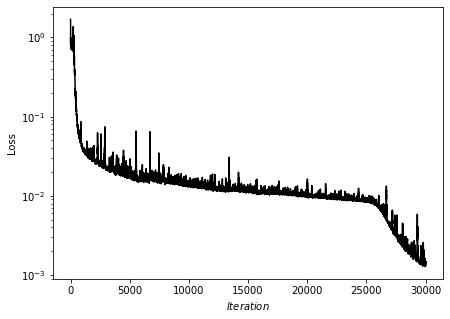

In [8]:
solver.plot_loss_history();

# vérification que ca fonctionne 

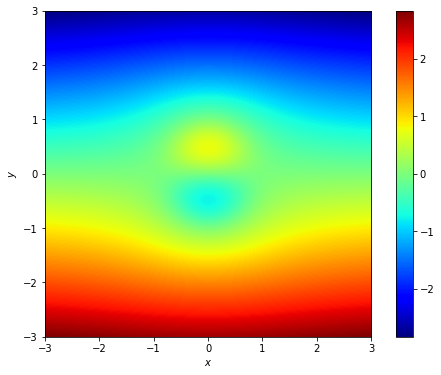

In [4]:
N = 500

# compute solution using PINN
x = np.linspace(-3,3,N)
y = np.linspace(-3,3,N)
xx, yy = np.meshgrid(x, y)

psi_0 = fun_psi_0(xx,yy)

# plot solution
fig = plt.figure(figsize=(9,6))
ax = fig.add_subplot(111)
ax.set_xlabel('$x$')
ax.set_ylabel('$y$')  
img = ax.imshow(psi_0, cmap='jet', origin='lower', extent=[-3.,3.,-3.,3.]);
fig.colorbar(img);

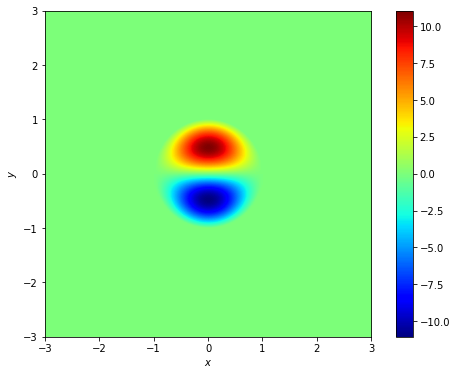

In [5]:
N = 500

# compute solution using PINN
x = np.linspace(-3,3,N)
y = np.linspace(-3,3,N)
xx, yy = np.meshgrid(x, y)

J_0 = fun_J_0(xx,yy)

# plot solution
fig = plt.figure(figsize=(9,6))
ax = fig.add_subplot(111)
ax.set_xlabel('$x$')
ax.set_ylabel('$y$')  
img = ax.imshow(J_0, cmap='jet', origin='lower', extent=[-3.,3.,-3.,3.]);
fig.colorbar(img);

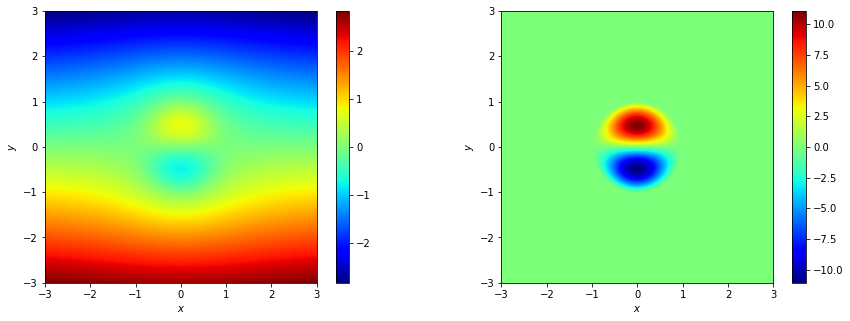

In [18]:
N = 500

x = np.linspace(-3,3,N)
y = np.linspace(-3,3,N)
xx, yy = np.meshgrid(x, y)

psi_0 = fun_psi_0(xx,yy)
J_0 = fun_J_0(xx,yy)

# plot
fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(15,5))
axs = axs.flatten()

axs[0].set_xlabel('$x$')
axs[0].set_ylabel('$y$')  
img0 = axs[0].imshow(psi_0, cmap='jet', origin='lower', extent=[-3.,3.,-3.,3.]);
cbar0 = plt.colorbar(img0, ax=axs[0])

axs[1].set_xlabel('$x$')
axs[1].set_ylabel('$y$')  
img1 = axs[1].imshow(J_0, cmap='jet', origin='lower', extent=[-3.,3.,-3.,3.]);
cbar1 = plt.colorbar(img1, ax=axs[1])

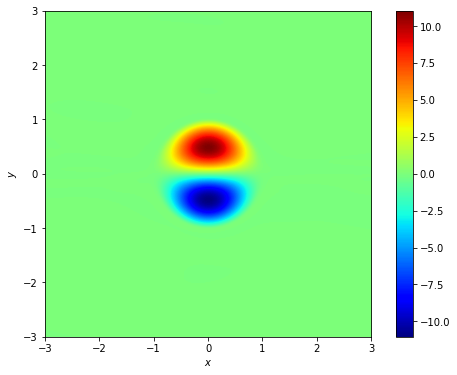

In [11]:
N = 600

# compute solution using PINN
xspace = np.linspace(-3,3,N)
yspace = np.linspace(-3,3,N)
tfinal = 0. * np.ones(N*N)

X, Y = np.meshgrid(xspace, yspace)
Xgrid = np.vstack([tfinal.flatten(), X.flatten(), Y.flatten()]).T
upred = model(tf.cast(Xgrid,DTYPE))

J = upred[:,2:3]

# reshape for plotting
J = J.numpy().reshape(N,N)

# plot solution
fig = plt.figure(figsize=(9,6))
ax = fig.add_subplot(111)
ax.set_xlabel('$x$')
ax.set_ylabel('$y$')  
img = ax.imshow(J, cmap='jet', origin='lower', extent=[-3,3.,-3.,3.]);
fig.colorbar(img);

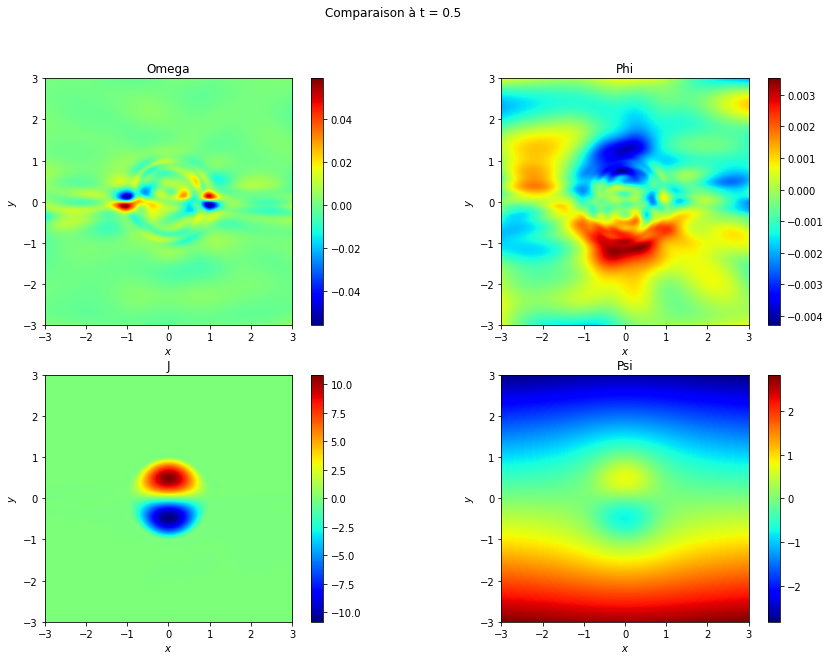

In [12]:
N = 500
t = 0.5

# compute solution using PINN
xspace = np.linspace(-3,3,N)
yspace = np.linspace(-3,3,N)
tfinal = t * np.ones(N*N)

X, Y = np.meshgrid(xspace, yspace)
Xgrid = np.vstack([tfinal.flatten(), X.flatten(), Y.flatten()]).T
u = model(tf.cast(Xgrid,DTYPE))

omega, phi, J, psi = u[:,0:1], u[:,1:2], u[:,2:3], u[:,3:4]

# reshape for plotting
omega = omega.numpy().reshape(N,N)
phi = phi.numpy().reshape(N,N)
J = J.numpy().reshape(N,N)
psi = psi.numpy().reshape(N,N)

# affichage
fig, axs = plt.subplots(nrows=2, ncols=2, figsize=(15,10))
axs = axs.flatten()

# plot omega
axs[0].set_xlabel('$x$')
axs[0].set_ylabel('$y$')
axs[0].set_aspect('equal')
img0 = axs[0].imshow(omega, cmap='jet', origin='lower', extent=[-3,3.,-3.,3.]);
cbar0 = plt.colorbar(img0, ax=axs[0])
axs[0].set_title('Omega')

# plot phi
axs[1].set_xlabel('$x$')
axs[1].set_ylabel('$y$')
axs[1].set_aspect('equal')
img1 = axs[1].imshow(phi, cmap='jet', origin='lower', extent=[-3,3.,-3.,3.]);
cbar1 = plt.colorbar(img1, ax=axs[1])
axs[1].set_title('Phi')

# plot J
axs[2].set_xlabel('$x$')
axs[2].set_ylabel('$y$')
axs[2].set_aspect('equal')
img2 = axs[2].imshow(J, cmap='jet', origin='lower', extent=[-3,3.,-3.,3.]);
cbar2 = plt.colorbar(img2, ax=axs[2])
axs[2].set_title('J')

# plot psi
axs[3].set_xlabel('$x$')
axs[3].set_ylabel('$y$')
axs[3].set_aspect('equal')
img3 = axs[3].imshow(psi, cmap='jet', origin='lower', extent=[-3,3.,-3.,3.]);
cbar3 = plt.colorbar(img3, ax=axs[3])
axs[3].set_title('Psi')

#fig.tight_layout()
plt.suptitle('Comparaison à t = {}'.format(t))
plt.show()

In [13]:
import requests

bot_token = '5169497350:AAHiAyn6D8q9QDoRzTC8HnQU8kYJ-M6xoDg'
bot_chatID = '1061558745'
send_text = 'https://api.telegram.org/bot' + bot_token + '/sendMessage?chat_id=' + bot_chatID + '&parse_mode=Markdown&text=' + 'Les calculs sont finito pipo (MHD)'

requests.get(send_text)

<Response [200]>